# Part 2 — Exploratory Data Analysis (EDA)

**Project:** Social Media and Stress Patterns
**Data:** `data/processed/social_media_stress_augmented.csv` (1,500 rows: 500 real + 1,000 synthetic) — the same dataset the models use.

This notebook contains the **actual EDA code**, section by section (the same code as `scripts/eda.py`).
Every section prints its findings in plain English and saves its charts to `reports/figures/`.

**9 story-driven charts — every chart answers one question:**

| # | Story |
|---|-------|
| 1 | The target: stress runs high and is imbalanced |
| 2 | The habit: most users spend 3–9 h/day on their phone |
| 3 | Who uses what: platforms are evenly spread |
| 4 | THE core finding: more screen time → more stress (r = +0.72) |
| 5 | The staircase: stress rises with every usage group (4.3 → 9.1) |
| 6 | The second link: more screen time → worse sleep (r = −0.72) |
| 7 | The whole web: correlation matrix at a glance |
| 8 | The non-story that matters: gender does NOT explain stress |
| 9 | Platforms and sleep: Instagram users sleep worst |

Charts without a story were removed on purpose (e.g. age and exercise correlate with almost nothing).

In [1]:
from pathlib import Path

import matplotlib

matplotlib.use("Agg")  # save charts to files instead of opening windows

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------------
# File locations
# ---------------------------------------------------------------
PROJECT = Path.cwd().resolve()
if not (PROJECT / "data" / "processed" / "social_media_stress_augmented.csv").exists():
    PROJECT = PROJECT.parent  # running from notebooks/ instead of the root
AUG_FILE = PROJECT / "data" / "processed" / "social_media_stress_augmented.csv"
FIG_DIR = PROJECT / "reports" / "figures"

# ---------------------------------------------------------------
# One consistent, professional look for every chart
# ---------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})

NAVY = "#1F4E79"
TEAL = "#2E86AB"
ORANGE = "#E67E22"
GREEN = "#27AE60"
RED = "#C0392B"
PURPLE = "#8E44AD"
PALETTE = [NAVY, TEAL, ORANGE, GREEN, RED, PURPLE]

NUMERIC_COLS = [
    "age",
    "daily_screen_time_hours",
    "sleep_quality",
    "stress_level",
    "days_without_social_media",
    "exercise_frequency_per_week",
    "happiness_index",
]


def styled_title(ax, title, subtitle=None):
    """Add a bold title plus a small grey subtitle under it."""
    ax.set_title(title, fontsize=13, fontweight="bold", pad=20)
    if subtitle:
        ax.text(0.5, 1.01, subtitle, transform=ax.transAxes,
                ha="center", fontsize=9, color="#595959", style="italic")


def save_chart(fig, name):
    """Save one chart to reports/figures/ and close it."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / name
    fig.savefig(path, bbox_inches="tight", dpi=150)
    plt.close(fig)
    print(f"    saved -> reports/figures/{name}")


# ================================================================

In [2]:
# Load the augmented dataset (the same 1,500 rows the models use)
df = pd.read_csv(AUG_FILE)
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns.\n")

Loaded 1500 rows x 11 columns.



## Section 1 - Overview

In [3]:
# SECTION 1 - OVERVIEW
# ================================================================
def overview(df):
    print("=" * 60)
    print("SECTION 1 - OVERVIEW")
    print("=" * 60)
    print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
    print("\nColumn types:")
    print(df.dtypes.to_string())
    print("\nNumeric summary:")
    print(df.describe().round(2).to_string())
    return df


# ================================================================

# Run this section now
df = overview(df)


SECTION 1 - OVERVIEW
Rows: 1500 | Columns: 11

Column types:
user_id                            str
age                              int64
gender                             str
daily_screen_time_hours        float64
sleep_quality                    int64
stress_level                     int64
days_without_social_media        int64
exercise_frequency_per_week      int64
social_media_platform              str
happiness_index                  int64
screen_time_group                  str

Numeric summary:
           age  daily_screen_time_hours  sleep_quality  stress_level  days_without_social_media  exercise_frequency_per_week  happiness_index
count  1500.00                  1500.00        1500.00       1500.00                    1500.00                      1500.00          1500.00
mean     33.41                     5.48           6.32          6.62                       3.18                         2.43             8.38
std      10.00                     1.73           1.63          1.

## Section 2 - Missing Values

In [4]:
# SECTION 2 - MISSING VALUES
# ================================================================
def missing_values_heatmap(df):
    """
    Count empty cells and report WHICH rows have them.
    The heatmap is only drawn when gaps actually exist.
    """
    print("\n" + "=" * 60)
    print("SECTION 2 - MISSING VALUES")
    print("=" * 60)
    total_missing = df.isna().sum().sum()
    print(f"Total missing values in the dataset: {total_missing}")

    found_any = False
    for index, row in df.iterrows():
        for col in df.columns:
            if pd.isna(row[col]):
                found_any = True
                label = row["user_id"] if "user_id" in df.columns else index
                print(f"  {label}: missing in '{col}'")
    if not found_any:
        print("No rows have missing values - every cell is filled.")

    if total_missing > 0:
        fig, ax = plt.subplots(figsize=(10, 3))
        sns.heatmap(df.isna(), cbar=False, yticklabels=False,
                    cmap=["#1F4E79", "#E67E22"], ax=ax)
        styled_title(ax, "Missing values map", "blue = filled, orange = missing")
        save_chart(fig, "eda_missing_values.png")
    else:
        print("(heatmap skipped - nothing to show on a clean dataset)")
    return df


# ================================================================

# Run this section now
df = missing_values_heatmap(df)



SECTION 2 - MISSING VALUES
Total missing values in the dataset: 0
No rows have missing values - every cell is filled.
(heatmap skipped - nothing to show on a clean dataset)


## Section 3 - The Target & The Key Habit (The Two Variables

In [5]:
# SECTION 3 - THE TARGET & THE KEY HABIT (the two variables
#             whose distributions actually matter)
# ================================================================
def univariate_numeric(df):
    """
    Only TWO distributions are drawn - stress (the target) and screen
    time (the key habit). The other numeric columns have no standalone
    story (age/exercise correlate with nothing; their means are
    reported as text in the overview), so no chart is drawn for them.
    """
    print("\n" + "=" * 60)
    print("SECTION 3 - THE TARGET & THE KEY HABIT")
    print("=" * 60)

    # ---- Story 1: the target ----
    col = "stress_level"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2),
                                   gridspec_kw={"width_ratios": [1.4, 1]})
    sns.histplot(df[col], kde=True, color=NAVY, alpha=0.85,
                 edgecolor="white", linewidth=0.5, ax=ax1)
    ax1.axvline(df[col].mean(), color=ORANGE, ls="--", lw=1.6,
                label=f"mean {df[col].mean():.2f}")
    ax1.axvline(df[col].median(), color=GREEN, ls=":", lw=1.8,
                label=f"median {df[col].median():.2f}")
    ax1.legend(loc="upper left", fontsize=9, frameon=False)
    styled_title(ax1, "Stress runs high",
                 "most people rate themselves 6-8 out of 10")
    sns.boxplot(x=df[col], color=TEAL, width=0.35, ax=ax2)
    ax2.annotate("only 9.7% are 'Low' stress", xy=(0.5, 0.5), xycoords="axes fraction",
                 ha="center", fontsize=9.5, color="#404040")
    styled_title(ax2, "The target is imbalanced",
                 "Low-stress is a small class -> weighted metrics later")
    save_chart(fig, "eda_stress_level.png")
    print(f"  STORY 1: stress mean {df[col].mean():.2f}, most mass in 6-8; "
          f"Low-stress is only 9.7% of users.")

    # ---- Story 2: the key habit ----
    col = "daily_screen_time_hours"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2),
                                   gridspec_kw={"width_ratios": [1.4, 1]})
    sns.histplot(df[col], kde=True, color=NAVY, alpha=0.85,
                 edgecolor="white", linewidth=0.5, ax=ax1)
    ax1.axvline(df[col].mean(), color=ORANGE, ls="--", lw=1.6,
                label=f"mean {df[col].mean():.2f} h")
    ax1.axvline(df[col].median(), color=GREEN, ls=":", lw=1.8,
                label=f"median {df[col].median():.2f} h")
    ax1.legend(loc="upper right", fontsize=9, frameon=False)
    styled_title(ax1, "Screen time: most users sit between 3 and 9 hours",
                 "a small group reaches 10+ hours a day")
    sns.boxplot(x=df[col], color=TEAL, width=0.35, ax=ax2)
    ax2.annotate("extremes: up to 10.8 h", xy=(0.5, 0.5), xycoords="axes fraction",
                 ha="center", fontsize=9.5, color="#404040")
    styled_title(ax2, "The habit we will test everywhere",
                 "screen time is the candidate driver of stress")
    save_chart(fig, "eda_daily_screen_time_hours.png")
    print(f"  STORY 2: screen time mean {df[col].mean():.2f} h, median "
          f"{df[col].median():.2f} h, max {df[col].max():.1f} h.")

    return df


def univariate_categorical(df):
    """Only the platform chart is kept - it answers 'who uses what'."""
    print("\n" + "=" * 60)
    print("SECTION 3b - WHO USES WHAT (platforms)")
    print("=" * 60)
    col = "social_media_platform"
    counts = df[col].value_counts()
    print(f"\n  {col} counts:")
    for label, n in counts.items():
        print(f"    {label}: {n} ({n / len(df) * 100:.1f}%)")

    fig, ax = plt.subplots(figsize=(8, 4.4))
    bars = sns.barplot(x=counts.values, y=counts.index,
                       color=NAVY, alpha=0.9, ax=ax)
    for bar, n in zip(ax.patches, counts.values):
        ax.text(bar.get_width() + 8, bar.get_y() + bar.get_height() / 2,
                f"{n}  ({n / len(df) * 100:.0f}%)", va="center",
                fontsize=9.5, color="#404040")
    ax.set_xlim(0, max(counts.values) * 1.18)
    styled_title(ax, "Platforms are evenly spread",
                 "LinkedIn, X and TikTok lead, but no app dominates")
    ax.set_xlabel("users")
    ax.set_ylabel("")
    save_chart(fig, "eda_social_media_platform_counts.png")
    print("  STORY 3: the six platforms are nearly balanced - the sample "
          "is not dominated by one app.")
    return df


# ================================================================

# Run this section now
df = univariate_numeric(df)



SECTION 3 - THE TARGET & THE KEY HABIT
    saved -> reports/figures/eda_stress_level.png
  STORY 1: stress mean 6.62, most mass in 6-8; Low-stress is only 9.7% of users.
    saved -> reports/figures/eda_daily_screen_time_hours.png
  STORY 2: screen time mean 5.48 h, median 5.55 h, max 11.1 h.


## Section 4 - The Core Relationships (The Two Big Stories)

In [6]:
# SECTION 4 - THE CORE RELATIONSHIPS (the two big stories)
# ================================================================
def bivariate(df):
    """
    Only the relationships with a story are drawn:
      * screen time vs stress   (r = +0.72)  - THE core finding
      * screen time vs sleep    (r = -0.72)  - the second link
      * stress by usage group   (the staircase)
    Exercise vs happiness is dropped on purpose: r = +0.01, no story.
    """
    print("\n" + "=" * 60)
    print("SECTION 4 - THE CORE RELATIONSHIPS")
    print("=" * 60)

    platforms = sorted(df["social_media_platform"].unique())
    platform_colors = dict(zip(platforms, PALETTE))

    # ---- Story 4: screen time vs stress ----
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.scatterplot(data=df, x="daily_screen_time_hours", y="stress_level",
                    hue="social_media_platform", palette=platform_colors,
                    alpha=0.6, s=45, edgecolor="none", ax=ax)
    sns.regplot(data=df, x="daily_screen_time_hours", y="stress_level",
                scatter=False, color=RED, line_kws={"lw": 2}, ax=ax)
    r = df["daily_screen_time_hours"].corr(df["stress_level"])
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8,
              title=None, frameon=False)
    styled_title(ax, "More screen time, more stress",
                 f"THE core finding · r = {r:+.2f} · each dot is one person")
    save_chart(fig, "eda_daily_screen_time_hours_vs_stress_level.png")
    print(f"  STORY 4: screen time vs stress, r = {r:+.2f}.")

    # ---- Story 5: the staircase ----
    groups = sorted(df["screen_time_group"].unique())
    fig, ax = plt.subplots(figsize=(8, 4.6))
    sns.boxplot(data=df, x="screen_time_group", y="stress_level",
                order=groups, palette=PALETTE[:len(groups)], width=0.55, ax=ax)
    means = df.groupby("screen_time_group")["stress_level"].mean()
    for i, g in enumerate(groups):
        ax.text(i, means[g] + 0.18, f"μ {means[g]:.2f}", ha="center",
                fontsize=9.5, color="#404040", fontweight="bold")
    ax.set_ylim(bottom=df["stress_level"].min() - 0.9)
    styled_title(ax, "The staircase: stress climbs with every usage group",
                 "4.3 -> 6.0 -> 7.6 -> 9.1 · no threshold, every hour counts")
    save_chart(fig, "eda_stress_level_by_screen_time_group.png")
    print("  STORY 5: stress rises monotonically across usage groups.")

    # ---- Story 6: screen time vs sleep ----
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.scatterplot(data=df, x="daily_screen_time_hours", y="sleep_quality",
                    color=TEAL, alpha=0.55, s=45, edgecolor="none", ax=ax)
    sns.regplot(data=df, x="daily_screen_time_hours", y="sleep_quality",
                scatter=False, color=RED, line_kws={"lw": 2}, ax=ax)
    r = df["daily_screen_time_hours"].corr(df["sleep_quality"])
    styled_title(ax, "More screen time, worse sleep",
                 f"the second link in the chain · r = {r:+.2f}")
    save_chart(fig, "eda_daily_screen_time_hours_vs_sleep_quality.png")
    print(f"  STORY 6: screen time vs sleep, r = {r:+.2f}.")

    # ---- Story 8 (non-story): stress by gender ----
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    sns.boxplot(data=df, x="gender", y="stress_level",
                palette=PALETTE[:3], width=0.5, ax=ax)
    means = df.groupby("gender")["stress_level"].mean()
    for i, g in enumerate(sorted(df["gender"].unique())):
        ax.text(i, means[g] + 0.15, f"μ {means[g]:.2f}", ha="center",
                fontsize=9.5, color="#404040", fontweight="bold")
    ax.set_ylim(bottom=df["stress_level"].min() - 0.8)
    styled_title(ax, "Gender does NOT explain stress",
                 "means are nearly identical (6.6 vs 6.6 vs 6.5) - habits do")
    save_chart(fig, "eda_stress_level_by_gender.png")
    print("  STORY 8: stress is essentially equal across genders - the "
          "signal is in habits, not demographics.")

    # ---- Story 9: sleep by platform ----
    fig, ax = plt.subplots(figsize=(8, 4.4))
    sns.boxplot(data=df, x="social_media_platform", y="sleep_quality",
                order=platforms, palette=PALETTE[:len(platforms)],
                width=0.55, ax=ax)
    means = df.groupby("social_media_platform")["sleep_quality"].mean()
    for i, g in enumerate(platforms):
        ax.text(i, means[g] + 0.15, f"μ {means[g]:.2f}", ha="center",
                fontsize=9.5, color="#404040", fontweight="bold")
    ax.set_ylim(bottom=df["sleep_quality"].min() - 0.8)
    styled_title(ax, "Instagram users sleep worst, LinkedIn best",
                 "a small platform effect worth remembering")
    plt.xticks(rotation=20)
    save_chart(fig, "eda_sleep_quality_by_social_media_platform.png")
    print("  STORY 9: sleep quality differs slightly by platform.")
    return df


# ================================================================

# Run this section now
df = bivariate(df)



SECTION 4 - THE CORE RELATIONSHIPS


    saved -> reports/figures/eda_daily_screen_time_hours_vs_stress_level.png
  STORY 4: screen time vs stress, r = +0.72.
    saved -> reports/figures/eda_stress_level_by_screen_time_group.png
  STORY 5: stress rises monotonically across usage groups.


    saved -> reports/figures/eda_daily_screen_time_hours_vs_sleep_quality.png
  STORY 6: screen time vs sleep, r = -0.72.
    saved -> reports/figures/eda_stress_level_by_gender.png
  STORY 8: stress is essentially equal across genders - the signal is in habits, not demographics.


    saved -> reports/figures/eda_sleep_quality_by_social_media_platform.png
  STORY 9: sleep quality differs slightly by platform.


/var/folders/dd/wck9v_55587d1bv52lzk0j800000gn/T/ipykernel_98789/4219600392.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="screen_time_group", y="stress_level",
/var/folders/dd/wck9v_55587d1bv52lzk0j800000gn/T/ipykernel_98789/4219600392.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="gender", y="stress_level",
/var/folders/dd/wck9v_55587d1bv52lzk0j800000gn/T/ipykernel_98789/4219600392.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="social_media_platform", y="sleep_quality",


## Section 5 - Correlation (The Whole Web)

In [7]:
# SECTION 5 - CORRELATION (the whole web)
# ================================================================
def correlations(df):
    print("\n" + "=" * 60)
    print("SECTION 5 - THE WHOLE WEB (correlation matrix)")
    print("=" * 60)
    corr = df[NUMERIC_COLS].corr()

    fig, ax = plt.subplots(figsize=(8.5, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
                center=0, vmin=-1, vmax=1, square=True,
                linewidths=0.6, linecolor="white",
                cbar_kws={"shrink": 0.8, "label": "correlation"}, ax=ax)
    styled_title(ax, "The whole web of relationships",
                 "red = opposites · blue = move together")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
    save_chart(fig, "eda_correlation_heatmap.png")

    print("\n  Strongest relationships:")
    pairs = []
    for i in range(len(NUMERIC_COLS)):
        for j in range(i + 1, len(NUMERIC_COLS)):
            col_a, col_b = NUMERIC_COLS[i], NUMERIC_COLS[j]
            pairs.append((abs(corr.loc[col_a, col_b]), col_a, col_b,
                          corr.loc[col_a, col_b]))
    for strength, col_a, col_b, value in sorted(pairs, reverse=True)[:5]:
        direction = "positive" if value > 0 else "negative"
        print(f"    {col_a} <-> {col_b}: {value:+.2f} ({direction})")
    print("  STORY 7: screen time is the hub of the whole network - its two "
          "links (stress +0.72, sleep -0.72) are the strongest in the table.")
    return df


# ================================================================

# Run this section now
df = correlations(df)



SECTION 5 - THE WHOLE WEB (correlation matrix)
    saved -> reports/figures/eda_correlation_heatmap.png

  Strongest relationships:
    daily_screen_time_hours <-> stress_level: +0.72 (positive)
    daily_screen_time_hours <-> sleep_quality: -0.72 (negative)
    stress_level <-> happiness_index: -0.69 (negative)
    daily_screen_time_hours <-> happiness_index: -0.68 (negative)
    sleep_quality <-> happiness_index: +0.61 (positive)
  STORY 7: screen time is the hub of the whole network - its two links (stress +0.72, sleep -0.72) are the strongest in the table.


## Section 6 - Outlier Scan (Text Only - No Chart, By Design)

In [8]:
# SECTION 6 - OUTLIER SCAN (text only - no chart, by design)
# ================================================================
def outlier_scan(df):
    print("\n" + "=" * 60)
    print("SECTION 6 - OUTLIER SCAN (IQR rule)")
    print("=" * 60)
    for col in NUMERIC_COLS:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        low_fence = q1 - 1.5 * iqr
        high_fence = q3 + 1.5 * iqr
        n_out = ((df[col] < low_fence) | (df[col] > high_fence)).sum()
        print(f"  {col}: {n_out} potential outlier(s) "
              f"(outside {low_fence:.1f} - {high_fence:.1f})")
    return df


# ================================================================
# MAIN
# ================================================================
def main():
    print("STARTING THE EDA")
    df = pd.read_csv(AUG_FILE)
    print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns from the augmented file.\n")

    df = overview(df)
    df = missing_values_heatmap(df)
    df = univariate_numeric(df)
    df = univariate_categorical(df)
    df = bivariate(df)
    df = correlations(df)
    df = outlier_scan(df)

    print("\nEDA FINISHED - 9 story-driven charts are in reports/figures/")

# Run this section now
df = outlier_scan(df)



SECTION 6 - OUTLIER SCAN (IQR rule)
  age: 0 potential outlier(s) (outside -0.5 - 67.5)
  daily_screen_time_hours: 5 potential outlier(s) (outside 0.5 - 10.4)
  sleep_quality: 2 potential outlier(s) (outside 2.0 - 10.0)
  stress_level: 3 potential outlier(s) (outside 3.0 - 11.0)
  days_without_social_media: 0 potential outlier(s) (outside -2.5 - 9.5)
  exercise_frequency_per_week: 6 potential outlier(s) (outside -2.0 - 6.0)
  happiness_index: 0 potential outlier(s) (outside 2.5 - 14.5)


**EDA result — the headline numbers (1,500 rows):**
- Screen time ↔ stress: **+0.72** · screen time ↔ sleep: **−0.72** · stress ↔ happiness: **−0.69**
- Stress rises step by step with usage: **4.3 → 6.0 → 7.6 → 9.1**
- Age and gender barely matter (|r| ≤ 0.06)
- Only 146 users (9.7%) are Low-stress → class imbalance expected in the tree

9 EDA charts:

### eda_correlation_heatmap.png


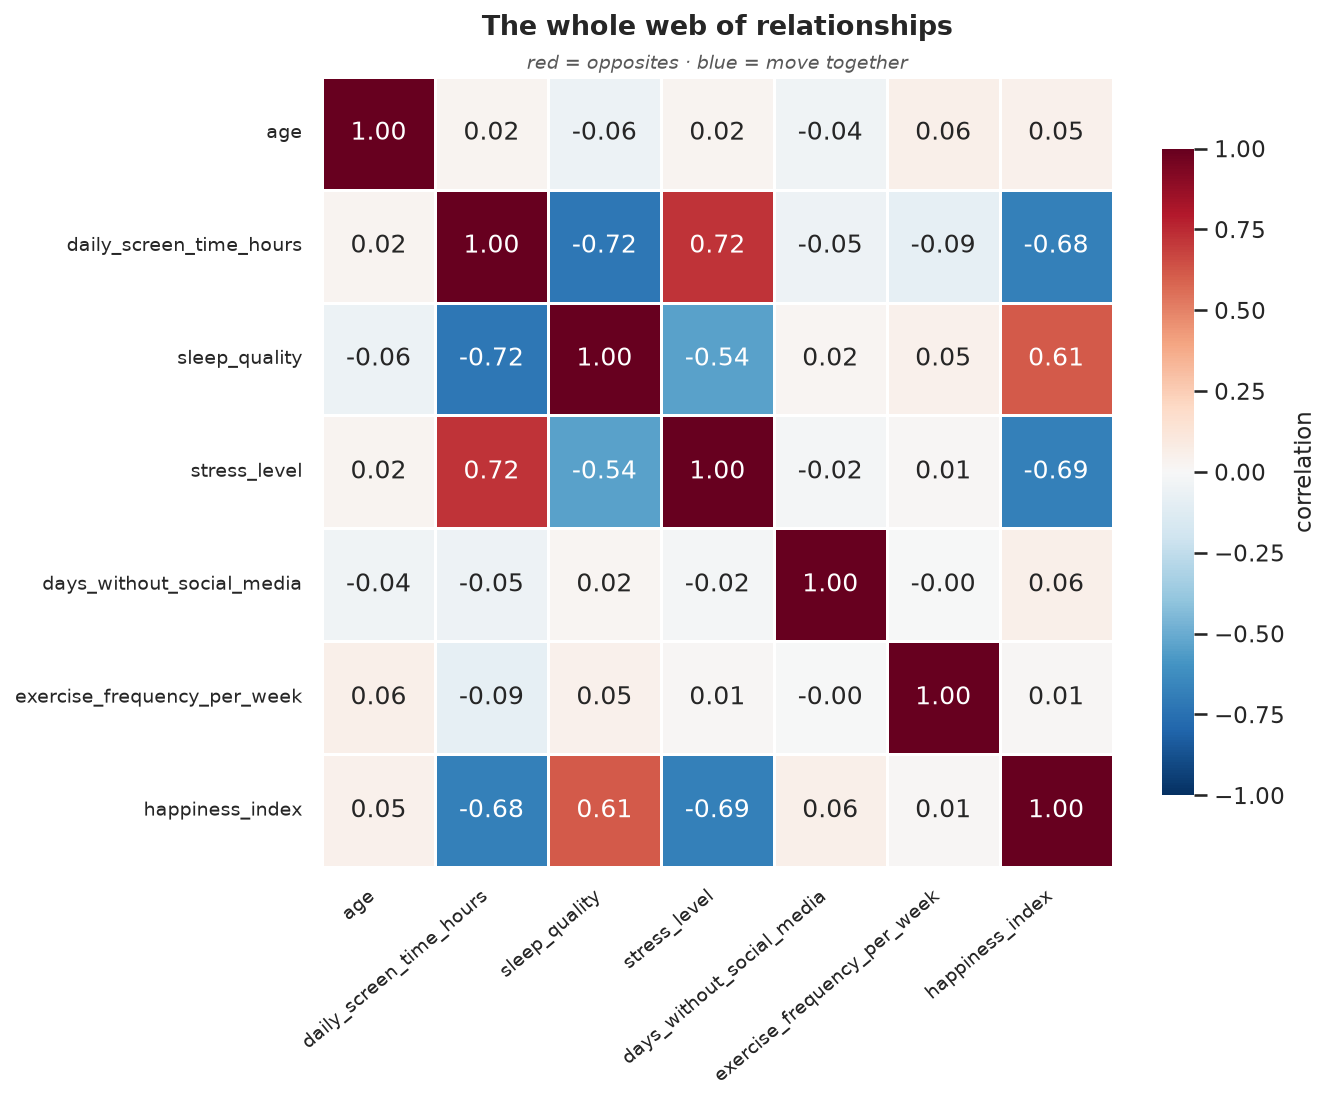


### eda_daily_screen_time_hours.png


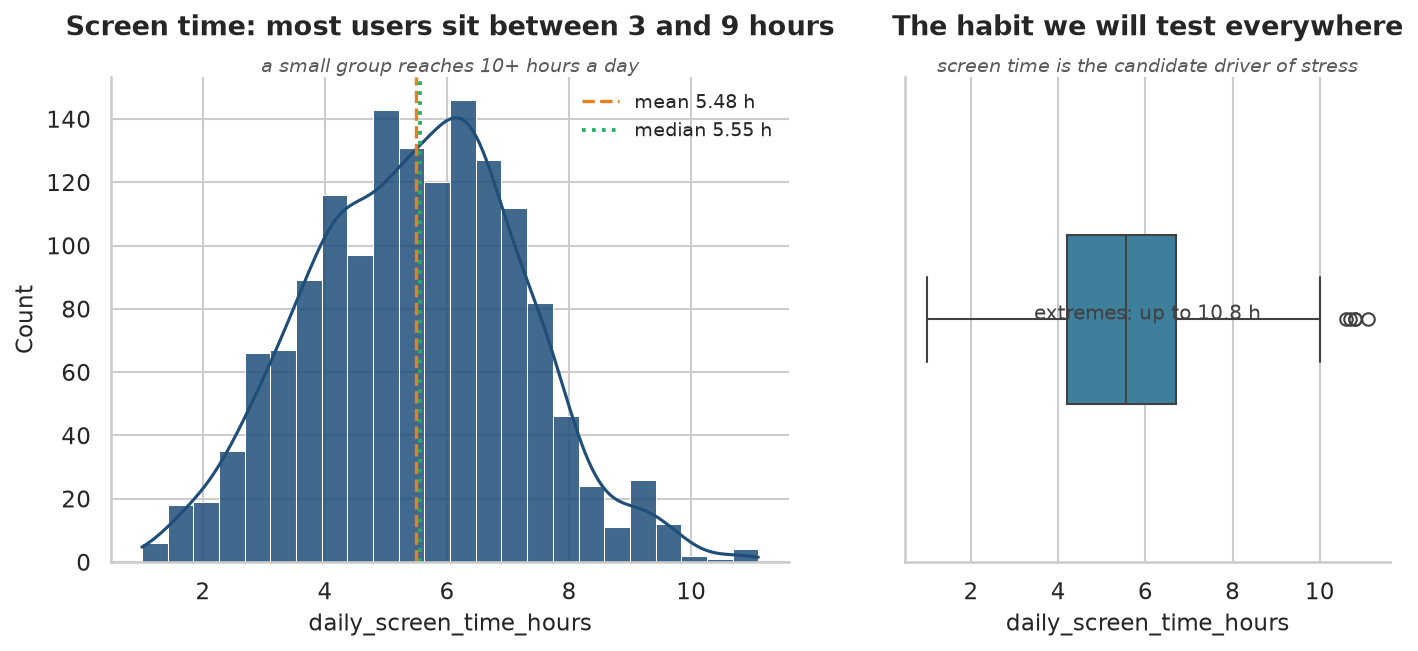


### eda_daily_screen_time_hours_vs_sleep_quality.png


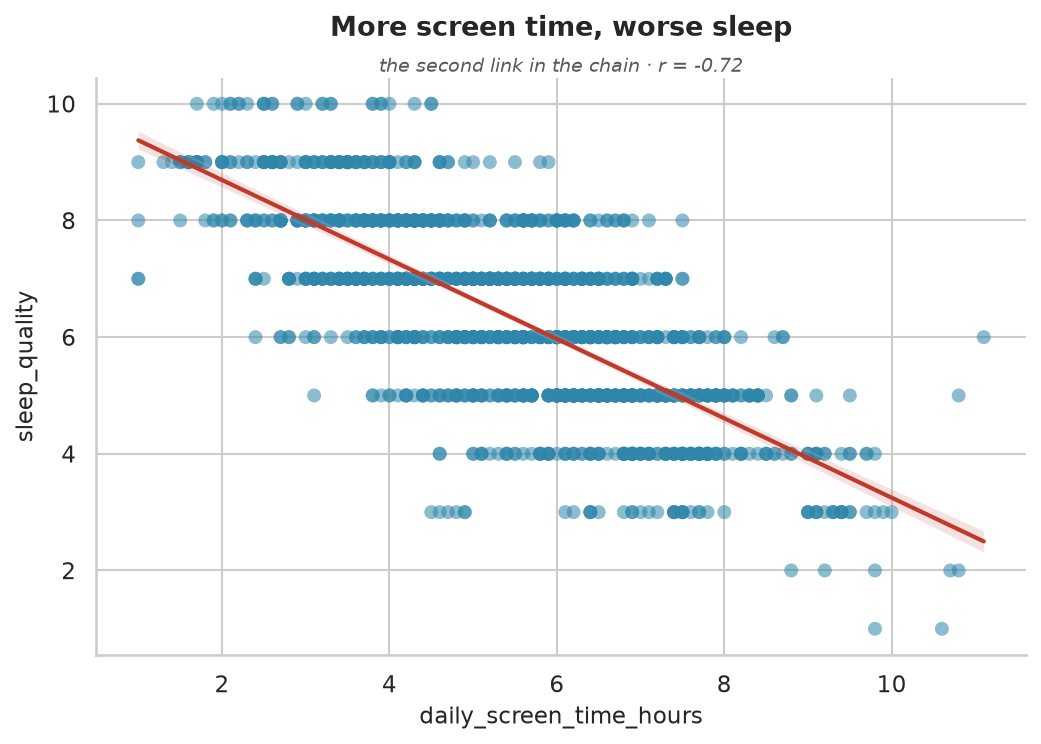


### eda_daily_screen_time_hours_vs_stress_level.png


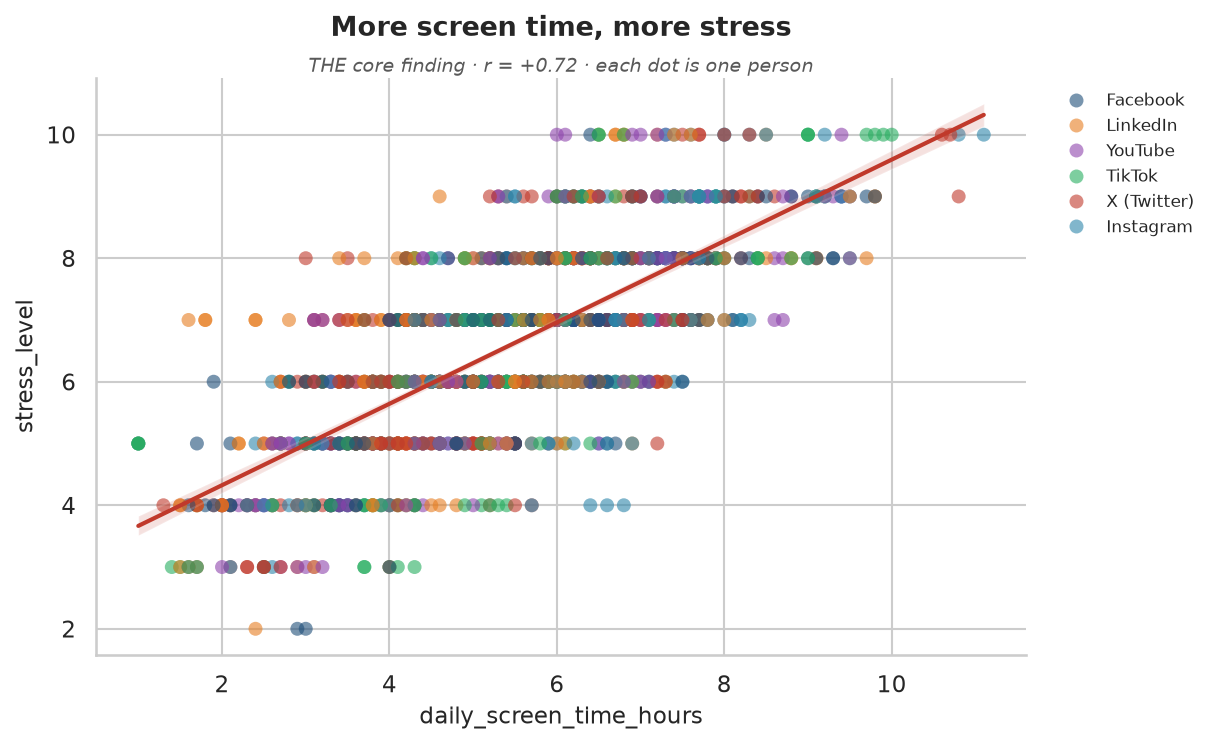


### eda_sleep_quality_by_social_media_platform.png


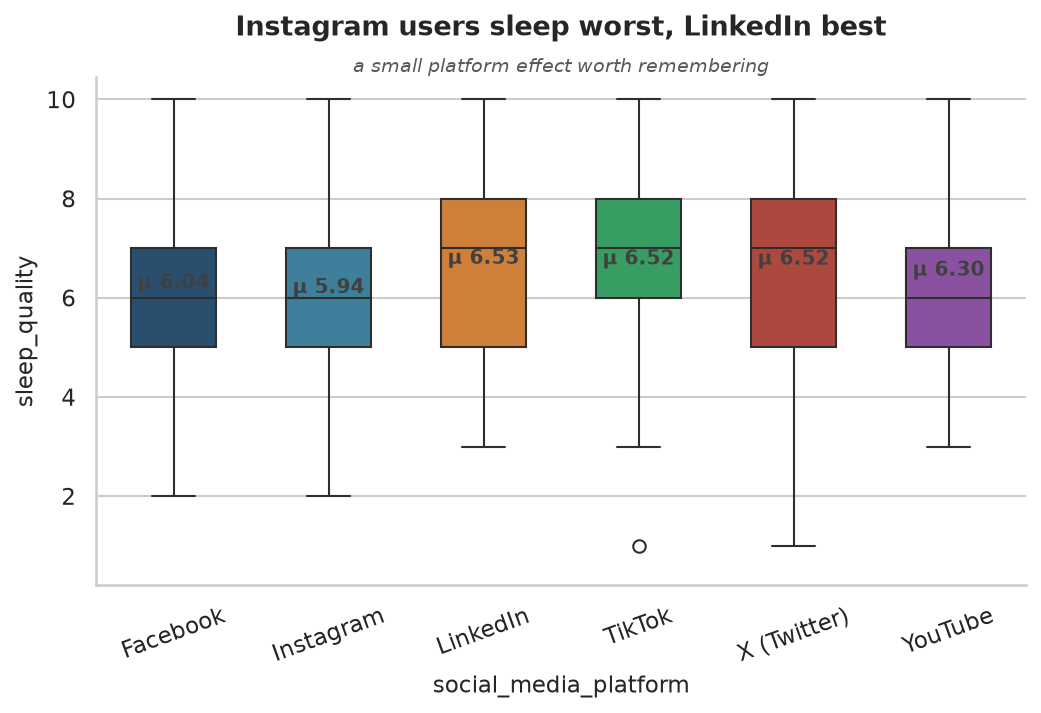


### eda_social_media_platform_counts.png


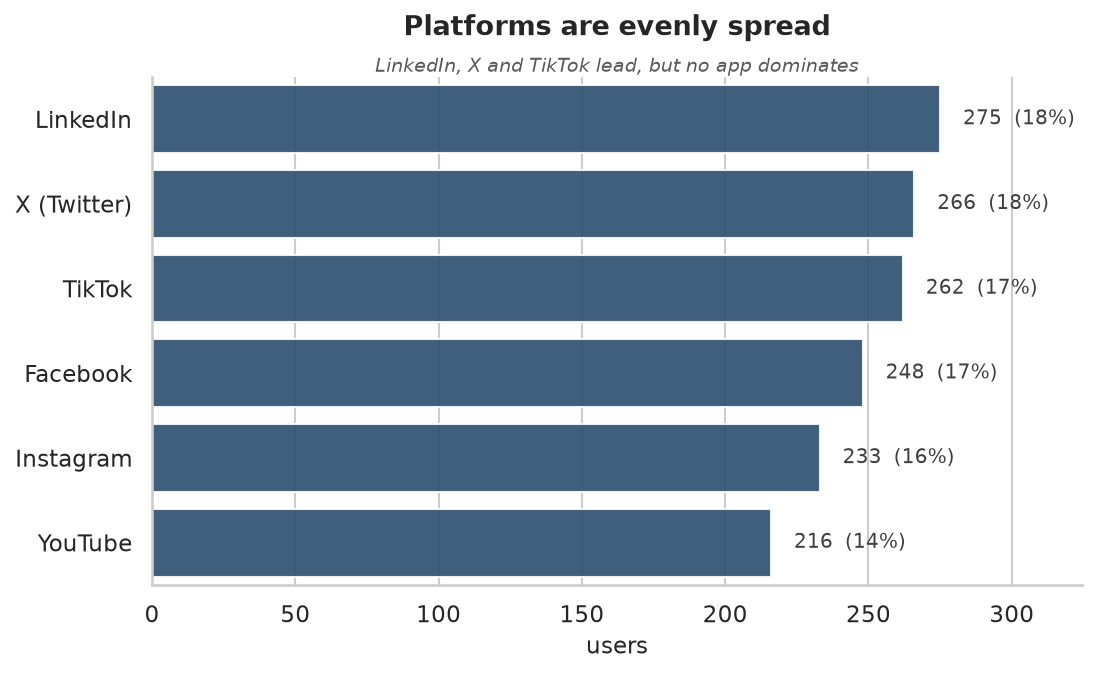


### eda_stress_level.png


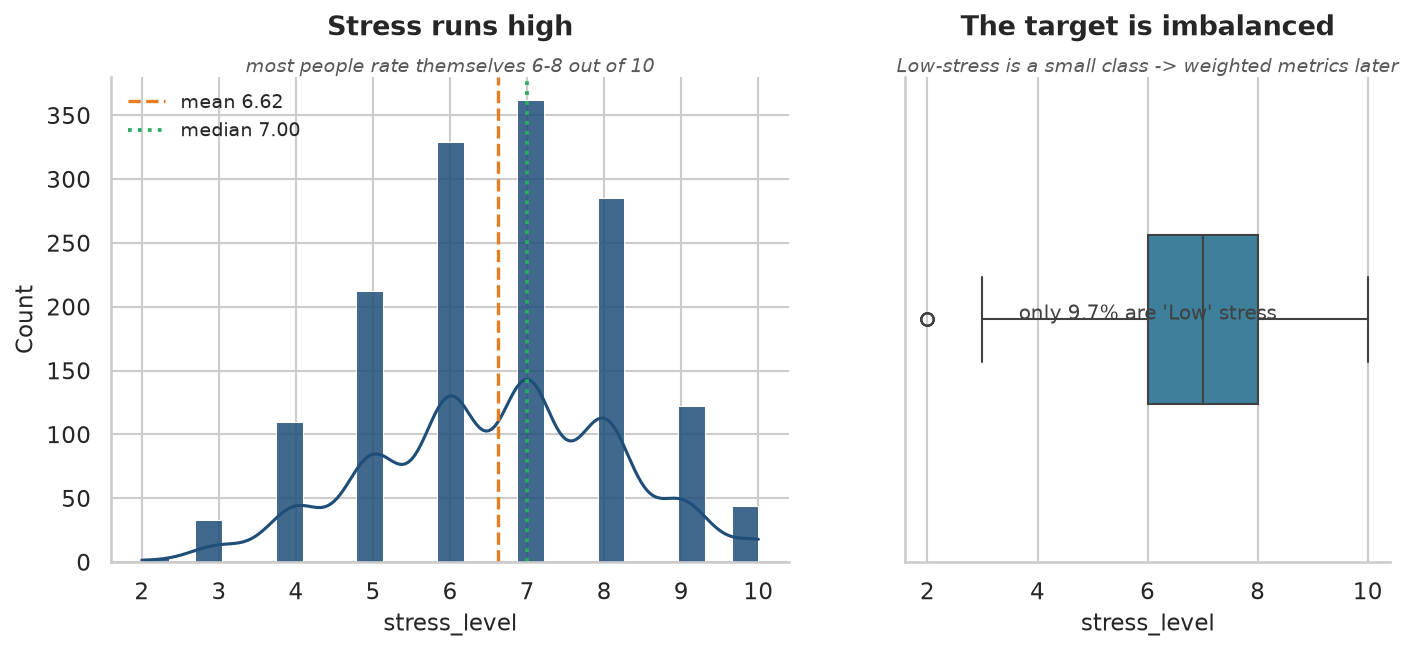


### eda_stress_level_by_gender.png


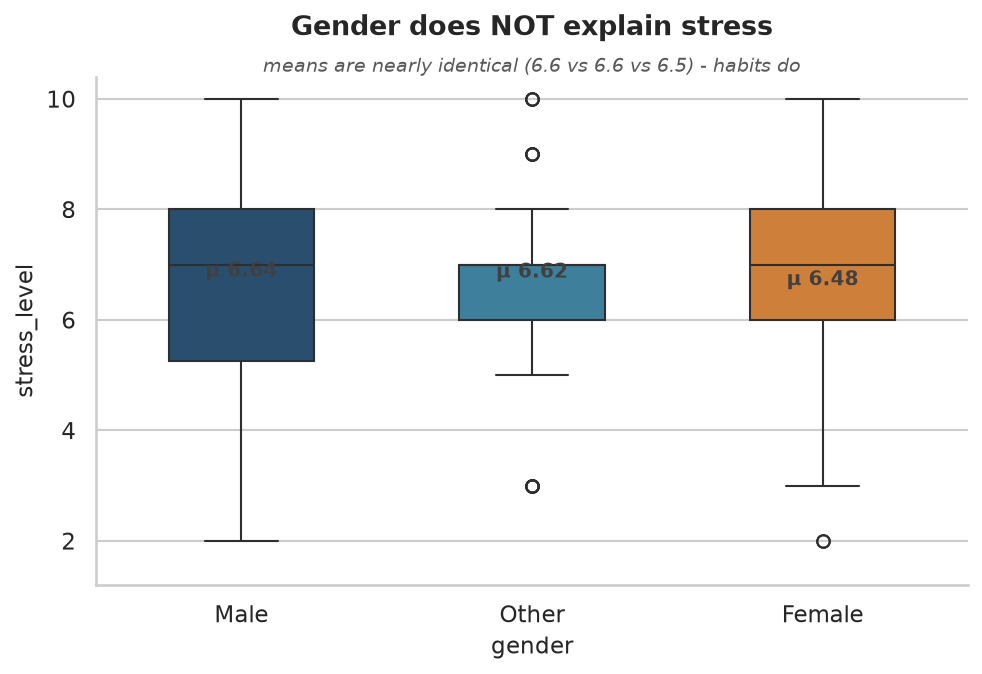


### eda_stress_level_by_screen_time_group.png


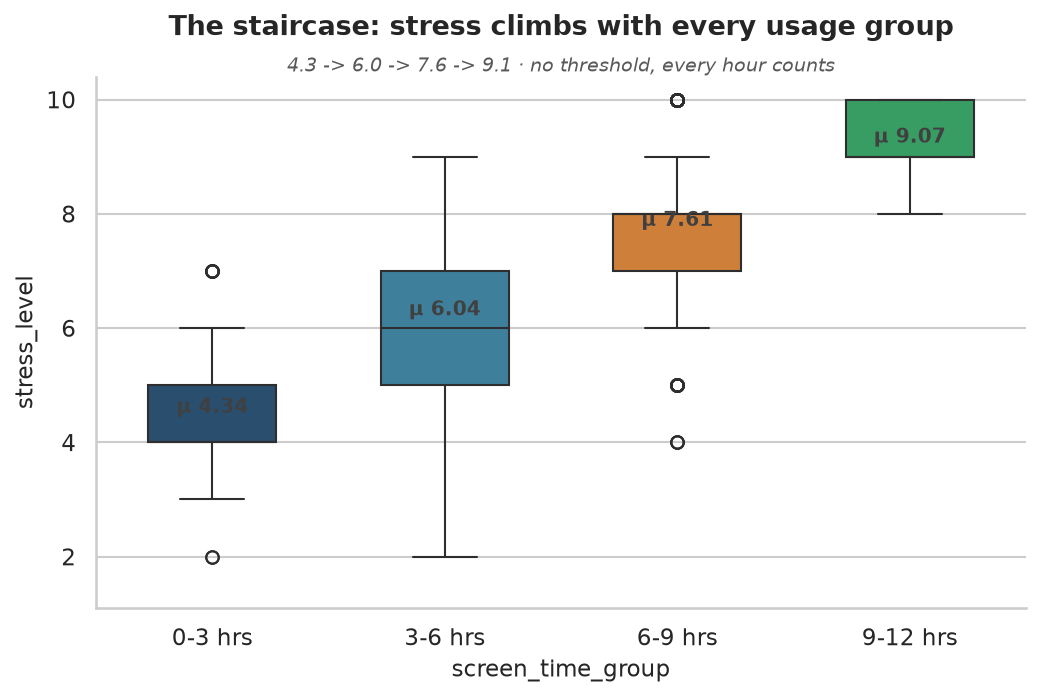

In [9]:
# Show every EDA chart inline so the whole analysis can be reviewed here.
from IPython.display import Image, display

figures = sorted((PROJECT / "reports" / "figures").glob("eda_*.png"))
print(f"{len(figures)} EDA charts:")

for path in figures:
    print("\n###", path.name)
    display(Image(filename=str(path)))